In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('credit_risk_dataset.csv')
df.head()


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
df['loan_status'].unique()

df['loan_status'].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

<Axes: xlabel='loan_status', ylabel='count'>

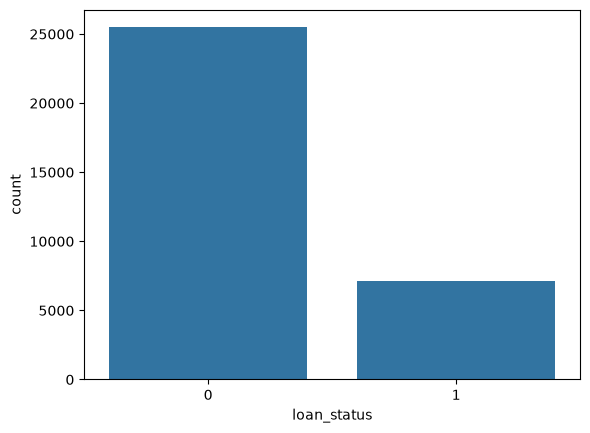

In [4]:
sns.countplot(x='loan_status', data=df)

In [5]:
df.shape
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.5 MB
None


In [6]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

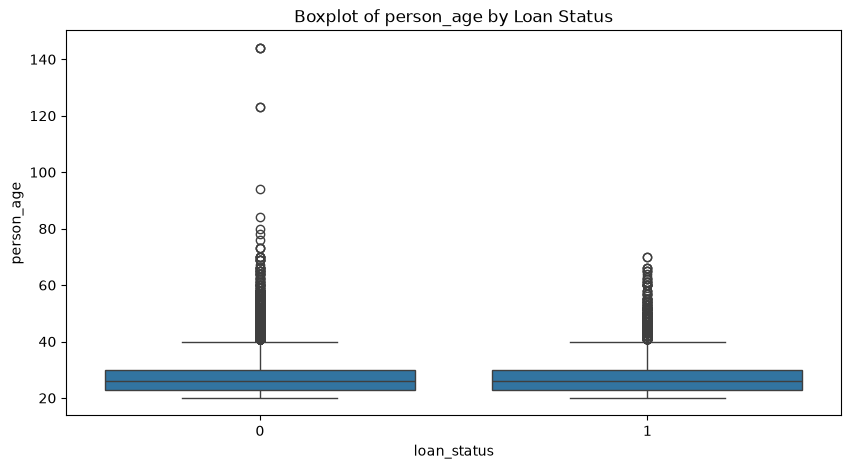

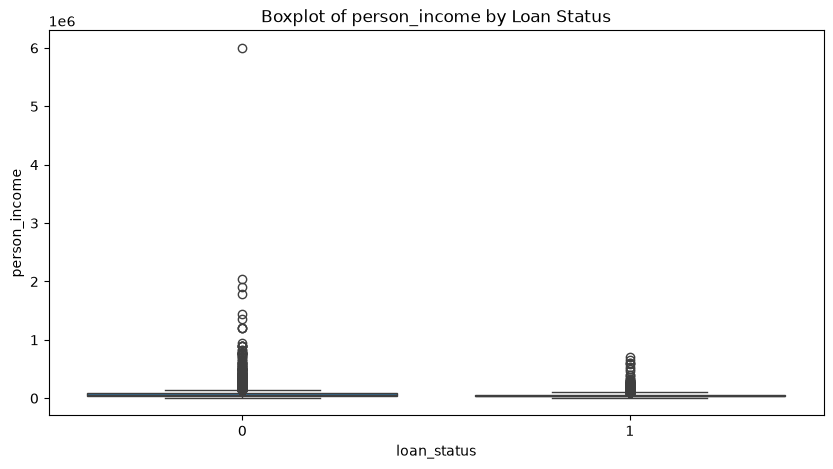

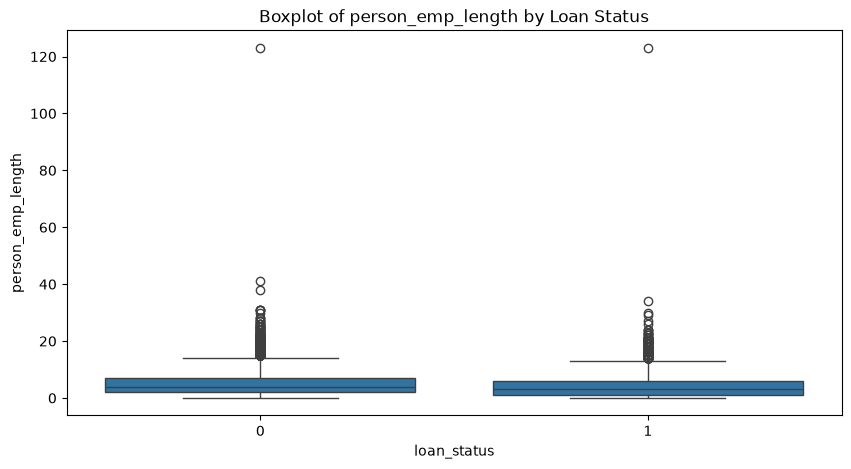

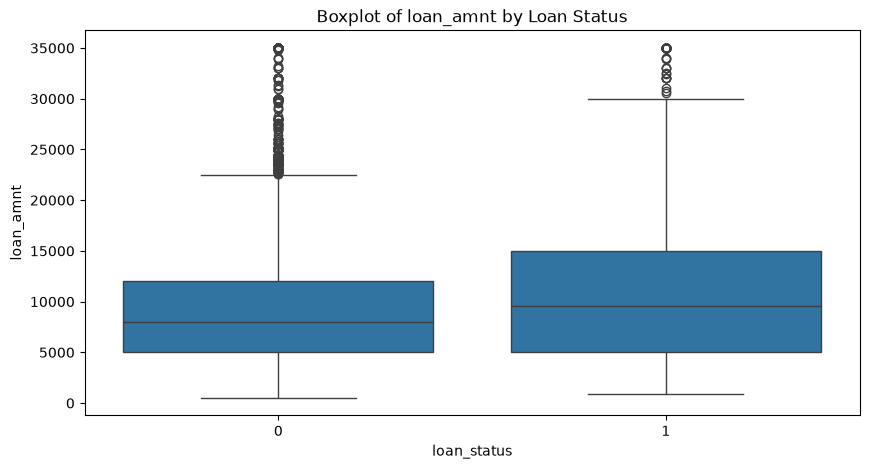

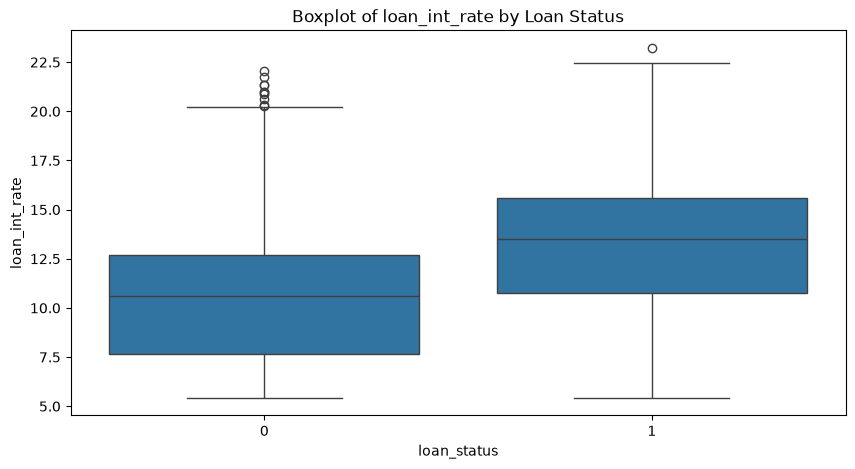

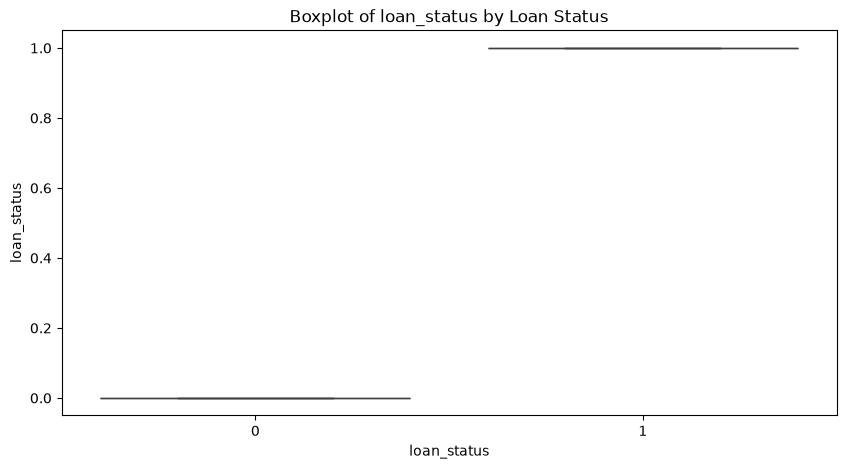

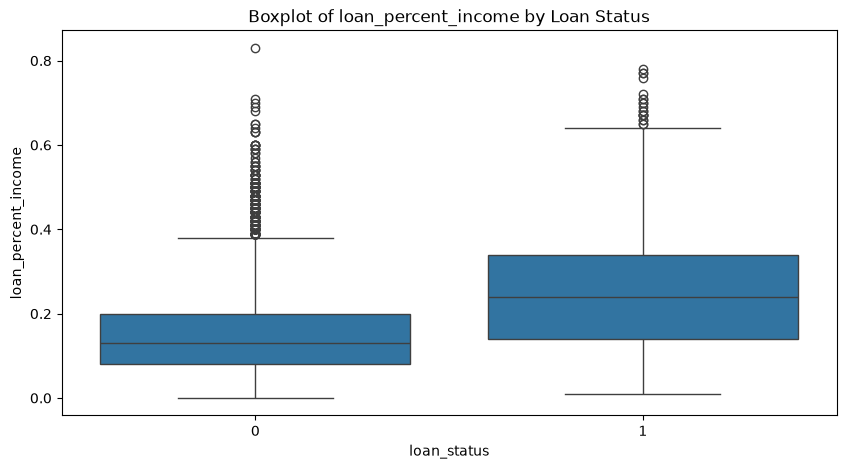

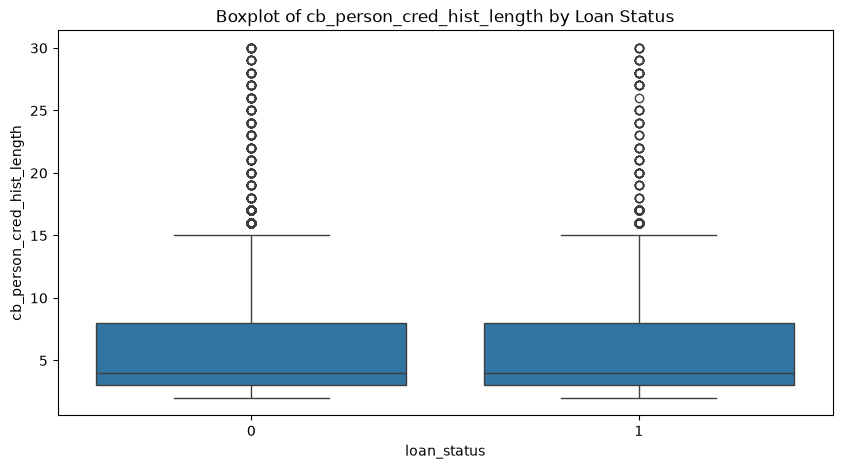

In [ ]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()

for i in num_cols:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x='loan_status', y=i, data=df)
    plt.title(f'Boxplot of {i} by Loan Status')
    plt.show()

In [11]:
(df['person_age'] > 100).sum()

np.int64(5)

In [14]:
(df['person_emp_length'] > 60).sum()

np.int64(2)

In [8]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


<Axes: >

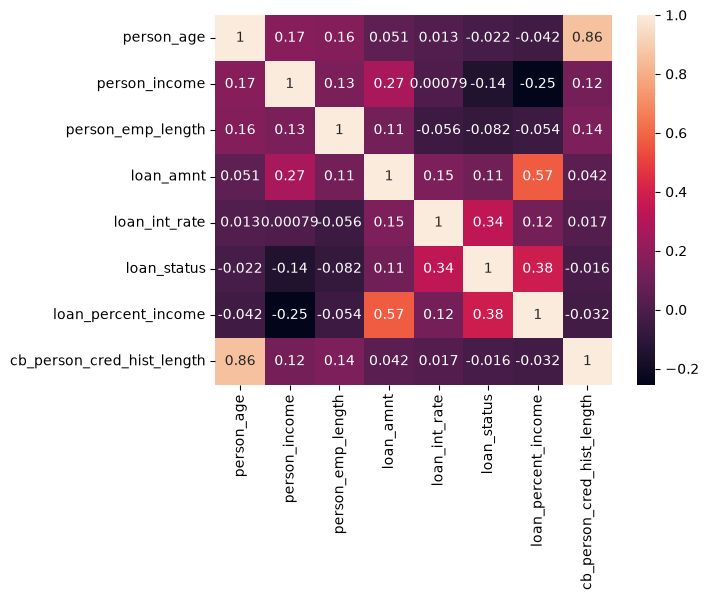

In [34]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

In [23]:
df_copy = df.copy()

print(f"Original shape: {df_copy.shape[0]}")

#remove dupliacte rows
df_copy.drop_duplicates(inplace=True)
print(f"Shape after removing duplicates: {df_copy.shape[0]}")

#remove ages below 18 and above 100
df_copy = df_copy[(df_copy['person_age'] >= 18)]
df_copy = df_copy[(df_copy['person_age'] <= 100)]

#remove employment length above 60 and outliers where employment length is greater than age
df_copy = df_copy[df_copy['person_emp_length'] <= df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length'] <= 60]

#remove loan amount less than or equal to 0
df_copy = df_copy[df_copy['loan_amnt'] > 0]

#check of interest rate looks realistic
print('loan interest rate from (min: 5.42 and max: 23.22)')

Original shape: 32581
Shape after removing duplicates: 32416
loan interest rate from (min: 5.42 and max: 23.22)


In [24]:
df_copy.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,31522.000000,3.152200e+04,31522.000000,31522.000000,28495.000000,31522.000000,31522.000000,31522.000000
mean,27.742529,6.650168e+04,4.782850,9663.771334,11.045220,0.215944,0.169658,5.816097
std,6.218713,5.275216e+04,4.037343,6334.787700,3.230786,0.411482,0.106296,4.063622
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.943800e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.600000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,8.000000e+04,7.000000,12500.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [25]:
x = df_copy.drop('loan_status', axis=1)
y = df_copy['loan_status']

In [27]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
#stratify imp for class imbalance, ensures that the train and test sets have the same proportion of classes as the original dataset

In [28]:
numeric_cols = [col for col in x_train.columns if x_train[col].dtype in ['int64', 'float64']]
categorical_cols = [col for col in x_train.columns if x_train[col].dtype == 'object']

In [33]:
#Class Weights inbuilt in logistic not in xgboost
y_train.value_counts()

zero, one = np.bincount(y_train)
scale_weights = zero/one
scale_weights

np.float64(3.6312213039485766)

In [35]:
#logistic regression : impute + scale numeric , impute + one hot encoding categorical (2 pipelines)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
#pipelines to prevent data leakage, imputer and scaler are fit on training data and then applied to test data
#imputer fills null values with mean for numeric and constant for categorical
#scaler standardizes numeric features, one hot encoder converts categorical features to binary vectors
#column transformer  sends respective columns to respective pipelines
preprocessor_lr = ColumnTransformer(
    transformers=[
        #pipeline for numeric columns: impute missing values with mean and scale the features
        ('impute_scale', Pipeline([
            ('imputer', SimpleImputer(strategy='mean')),
            ('scaler', StandardScaler())
        ]), numeric_cols),
        #pipeline for categorical columns: impute missing values with a constant value and one-hot encode the features
        ('impute_onehot', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

In [ ]:

preprocessor_xg = ColumnTransformer(
    transformers=[
        #pipeline for numeric columns: impute missing values with mean and scale the features
        ('impute_scale', Pipeline([
            ('imputer', SimpleImputer(strategy='mean')),
            ('scaler', StandardScaler())
        ]), numeric_cols),
        #pipeline for categorical columns: impute missing values with a constant value and one-hot encode the features
        ('impute_onehot', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)